[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mmazurek-wat/labs/blob/main/dist/student/nlp/08_finetuning_pretrained.ipynb)
**Natural Language Processing** · Lab NLP-08

> ⚡ This lab runs faster on a GPU. In Colab: *Runtime → Change runtime type → T4 GPU*. It also works (more slowly) on CPU.

# Lab NLP-08: Fine-tuning a pretrained Transformer (Hugging Face)

**Learning goals** - after this lab you will be able to:
- explain *transfer learning* in NLP: pretraining a Transformer on raw text, then adapting it to a task with few
  labelled examples,
- load a pretrained model and its tokenizer from the Hugging Face Hub (`AutoTokenizer`, `AutoModel`),
- explain and implement **WordPiece** subword tokenisation, and use special tokens and the attention mask,
- use a frozen pretrained encoder as a **feature extractor** (masked mean pooling + logistic regression),
- **fine-tune** the whole model with a classification head, AdamW, learning-rate warmup and gradient clipping,
- compare the fine-tuned Transformer with the LSTM and lexicon baselines from lab NLP-04 on the same data.

**How to work with this notebook**
1. Read each *Theory* section before the task that follows it.
2. Fill in every cell that contains `# YOUR CODE HERE` (delete the `raise NotImplementedError()` line).
3. Run the test cell under each task - it prints ✅ when your implementation is correct.
4. Answer the questions marked ✏️ in the markdown cells.

## 0. Setup
We use PyTorch and the Hugging Face `transformers` library (both preinstalled on Google Colab; the cell below
installs `transformers` if it is missing). The pretrained model (about 250 MB) is downloaded from the Hugging Face
Hub on first use.

Use a **GPU runtime** (*Runtime → Change runtime type → T4 GPU*): fine-tuning then takes about a minute.
Everything also runs on a CPU, but the whole notebook then takes about 10 minutes (most of it fine-tuning).

In [1]:
import sys
print(sys.executable)

/home/kb412/miniconda3/envs/ml/bin/python


In [4]:
import importlib.util
import subprocess
import sys


def ensure(package: str, module: str | None = None) -> None:
    """pip-install `package` if `module` cannot be imported (e.g. on a fresh Colab runtime)."""
    if importlib.util.find_spec(module or package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])


ensure("transformers")

import csv
import time
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import transformers
from sklearn.linear_model import LogisticRegression
from torch.utils.data import DataLoader
from transformers import AutoModel, AutoTokenizer, DistilBertConfig

transformers.logging.set_verbosity_error()  # hide the long "some weights were not used" loading report
transformers.logging.disable_progress_bar()

IN_COLAB = "google.colab" in sys.modules
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| transformers", transformers.__version__)

device: cuda | transformers 5.24.0


The same small evaluation helpers as in lab NLP-04.

In [5]:
def stratified_split(labels: np.ndarray, test_size: float, seed: int) -> tuple[np.ndarray, np.ndarray]:
    """Random split of the indices 0..N-1 that keeps the class proportions in both parts."""
    split_rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for c in np.unique(labels):
        idx = np.flatnonzero(labels == c)
        split_rng.shuffle(idx)
        n_test = int(round(test_size * len(idx)))
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    return split_rng.permutation(train_idx), split_rng.permutation(test_idx)


def accuracy(y_true, y_pred) -> float:
    return float(np.mean(np.asarray(y_true).astype(int) == np.asarray(y_pred).astype(int)))


def confusion_matrix(y_true, y_pred) -> np.ndarray:
    """2x2 matrix: rows = true class (0, 1), columns = predicted class (0, 1)."""
    cm = np.zeros((2, 2), dtype=int)
    np.add.at(cm, (np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)), 1)
    return cm


def plot_confusion(ax, cm: np.ndarray, title: str) -> None:
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            color = "white" if cm[i, j] > cm.max() / 2 else "black"
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["negative", "positive"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["negative", "positive"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)

## 1. The data: Amazon reviews of unlocked mobile phones (as in lab NLP-04)

We reuse the dataset, the cleaning and the **exact same** random sample and splits as lab NLP-04, so the results
can be compared with the LSTM: duplicate review texts are removed, 20 000 reviews are sampled with seed 42, and the
star rating is recoded into a binary sentiment (`Rating >= 3` → positive (1), `Rating < 3` → negative (0)).
The split uses seed 10: 30 % test, and 10 % of the rest for validation.

In [6]:
DATA_URL = "https://eduds.blob.core.windows.net/nlp/Amazon_Unlocked_Mobile.csv.zip"
zip_path = Path("Amazon_Unlocked_Mobile.csv.zip")
csv_path = Path("Amazon_Unlocked_Mobile.csv")

if not csv_path.exists():
    if not zip_path.exists():
        print("downloading ...")
        urlretrieve(DATA_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zfile:
        zfile.extractall()


def parse_rating(value: str) -> int | None:
    try:
        return int(float(value))
    except (TypeError, ValueError):
        return None


csv.field_size_limit(10_000_000)  # some reviews are very long
seen: set[str] = set()
unique_reviews: list[tuple[str, int]] = []
with open(csv_path, encoding="utf-8", errors="replace", newline="") as f:
    for row in csv.DictReader(f):
        text, rating = (row.get("Reviews") or "").strip(), parse_rating(row.get("Rating"))
        if text and rating is not None and text not in seen:
            seen.add(text)
            unique_reviews.append((text, rating))
del seen
print("unique non-empty reviews:", len(unique_reviews))

N_SAMPLES = 20_000
pick = rng.choice(len(unique_reviews), size=N_SAMPLES, replace=False)
texts = [unique_reviews[i][0] for i in pick]
ratings = np.array([unique_reviews[i][1] for i in pick])
labels = (ratings >= 3).astype(int)

train_val_idx, test_idx = stratified_split(labels, test_size=0.3, seed=10)
inner_train, inner_val = stratified_split(labels[train_val_idx], test_size=0.1, seed=10)
train_idx, val_idx = train_val_idx[inner_train], train_val_idx[inner_val]
print(f"lab NLP-04 splits - train: {len(train_idx)}, validation: {len(val_idx)}, test: {len(test_idx)}")

unique non-empty reviews: 162490
lab NLP-04 splits - train: 12600, validation: 1400, test: 6000


### Smaller subsets
DistilBERT, the model we fine-tune, has about **66 million** parameters, more than 100 times as many as the LSTM
of lab NLP-04 (0.58 million). To keep the lab fast (also on a CPU) we work with random subsets of the NLP-04 splits:

- `N_FINETUNE = 2000` training reviews - **six times fewer** than the 12 600 the LSTM was trained on,
- 1000 validation and 2000 test reviews (a random part of the NLP-04 test set).

The index arrays are already in random order, so taking the first $n$ gives a random subset. The validation and
test reviews are then **sorted by length**: consecutive reviews have similar lengths, so each mini-batch needs
little padding and prediction is about twice as fast (the order does not matter for evaluation).

In [7]:
N_FINETUNE, N_VAL, N_TEST = 2000, 1000, 2000

ft_idx = train_idx[:N_FINETUNE]
val_sub = sorted(val_idx[:N_VAL], key=lambda i: len(texts[i]))
test_sub = sorted(test_idx[:N_TEST], key=lambda i: len(texts[i]))

texts_ft, y_ft = [texts[i] for i in ft_idx], labels[ft_idx]
texts_val, y_val = [texts[i] for i in val_sub], labels[val_sub]
texts_test, y_test = [texts[i] for i in test_sub], labels[test_sub]
ratings_test = ratings[test_sub]
print(f"fine-tuning: {len(texts_ft)}, validation: {len(texts_val)}, test: {len(texts_test)}")
print(f"share of positive reviews - fine-tuning: {y_ft.mean():.3f}, test: {y_test.mean():.3f}")

majority_acc = max(y_test.mean(), 1 - y_test.mean())
print(f"majority-class baseline accuracy on test: {majority_acc:.3f}")

fine-tuning: 2000, validation: 1000, test: 2000
share of positive reviews - fine-tuning: 0.725, test: 0.729
majority-class baseline accuracy on test: 0.729


## 2. Theory: pretrained Transformers and transfer learning

The LSTM of lab NLP-04 started from **random** weights: everything it knows about English - word meanings,
negation, syntax - it had to learn from 12 600 labelled phone reviews. **Transfer learning** splits this into two
stages:

1. **Pretraining** (done once, by someone with a lot of compute): a large Transformer encoder is trained on
   billions of words of raw, *unlabelled* text with a self-supervised objective. BERT (Devlin et al., 2019) uses
   **masked language modelling**: 15 % of the tokens are hidden and the model predicts them from both sides,
   e.g. *"The battery [MASK] all day."* → *lasts*. To do this well, the model must learn which words fit which
   contexts - a lot of syntax and semantics ends up in its weights.
2. **Fine-tuning** (cheap, done by us): a small task-specific **head** is put on top of the pretrained encoder and
   the whole network is trained for a few epochs on the labelled data of our task.

The encoder turns a sequence of $T$ tokens into $T$ **contextual embeddings** $\mathbf{h}_1, \dots,
\mathbf{h}_T \in \mathbb{R}^{d}$: unlike word2vec (lab NLP-03), the vector of *"charge"* depends on whether the
sentence is about a battery or a bill.

We use **DistilBERT** (`distilbert-base-uncased`, Sanh et al., 2019): a 6-layer version of BERT-base ($d = 768$,
12 attention heads) trained by *knowledge distillation* to imitate BERT. It is 40 % smaller and 60 % faster
while keeping about 97 % of BERT's performance on the GLUE benchmark. "uncased" means the text is lowercased.

**The Hugging Face Hub** hosts hundreds of thousands of pretrained models. The `transformers` library loads any
of them by name with the `Auto*` classes, which read the model's configuration and pick the right architecture:

```python
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")  # text -> token ids
encoder = AutoModel.from_pretrained("distilbert-base-uncased")        # token ids -> contextual embeddings
```

A model and its tokenizer always belong together: the model's embedding table is indexed by the tokenizer's ids.

In [8]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME).to(device)

cfg = encoder.config
print(f"{type(encoder).__name__}: {cfg.n_layers} layers, hidden size {cfg.dim}, {cfg.n_heads} heads, "
      f"max. {cfg.max_position_embeddings} positions")
print(f"parameters: {sum(p.numel() for p in encoder.parameters()) / 1e6:.1f} M")
print(f"vocabulary: {tokenizer.vocab_size} tokens")

DistilBertModel: 6 layers, hidden size 768, 12 heads, max. 512 positions
parameters: 66.4 M
vocabulary: 30522 tokens


## 3. Theory: subword tokenisation with WordPiece

In lab NLP-04 every word outside the vocabulary became `<oov>`: rare product names, typos (*"batteryyy"*) and
new words were lost. A pretrained model needs a fixed vocabulary that still covers **any** text. BERT's solution
is **WordPiece**, a *subword* vocabulary of about 30 000 units: frequent words are single tokens, rare words are
split into pieces. A piece that continues a word is written with the prefix `##`:

`unboxing` → `un`, `##box`, `##ing` &nbsp;&nbsp;&nbsp; `verizon` → `ve`, `##riz`, `##on`

Tokenisation has two steps:

1. **Pre-tokenisation** (rule-based): lowercase, strip accents, split on whitespace and punctuation:
   *"Doesn't work!"* → `doesn`, `'`, `t`, `work`, `!`.
2. **WordPiece** on every word, *greedy longest-match-first*:
   - start at the beginning of the word and find the **longest** prefix that is in the vocabulary,
   - emit it and continue from where it ended; pieces after the first must be in the vocabulary **with** the
     `##` prefix,
   - if at some position not even a single character matches, the **whole word** becomes `[UNK]`; a word longer
     than 100 characters becomes `[UNK]` as well.

Because the vocabulary contains all single letters and digits (also as `##` pieces), `[UNK]` is very rare: only
for unusual symbols such as emoji.

### Task 1 - WordPiece
Implement `wordpiece(word, vocab, unk_token="[UNK]", max_chars=100)` for a **single, pre-tokenised word** (already
lowercased, no spaces or punctuation). `vocab` is a `dict` (or any container supporting `in`) of the vocabulary
entries. Return the list of pieces, `[unk_token]` if the word cannot be tokenised or has more than `max_chars`
characters, and `[]` for the empty string.

The tests compare your result with the real tokenizer: `tokenizer.tokenize(word)`.

In [13]:
def wordpiece(word: str, vocab, unk_token: str = "[UNK]", max_chars: int = 100) -> list[str]:
    if len(word) == 0:
        return []
    if len(word) > max_chars:
        return [unk_token]

    pieces = []
    start = 0
    while start < len(word):
        end = len(word)
        cur_piece = None
        while start < end:
            piece = word[start:end]
            if start > 0:
                piece = "##" + piece
            if piece in vocab:
                cur_piece = piece
                break
            end -= 1
        if cur_piece is None:
            return [unk_token]
        pieces.append(cur_piece)
        start = end
    return pieces

In [14]:
# Tests for Task 1
_toy_vocab = {"un", "lock", "##lock", "##locked", "##ed", "##s", "a", "##a"}
assert wordpiece("unlocked", _toy_vocab) == ["un", "##locked"], "take the LONGEST matching piece"
assert wordpiece("locks", _toy_vocab) == ["lock", "##s"]
assert wordpiece("aaa", _toy_vocab) == ["a", "##a", "##a"]
assert wordpiece("unz", _toy_vocab) == ["[UNK]"], "a word that cannot be covered becomes a single [UNK]"
assert wordpiece("edlock", _toy_vocab) == ["[UNK]"], "'##ed' may not start a word"
assert wordpiece("", _toy_vocab) == []
assert wordpiece("a" * 101, _toy_vocab) == ["[UNK]"] and len(wordpiece("a" * 100, _toy_vocab)) == 100

_vocab = tokenizer.get_vocab()
for _word in ["phone", "unlocked", "unboxing", "verizon", "batteryyy", "xyzzy", "4g", "motorola", "a☃b"]:
    assert wordpiece(_word, _vocab) == tokenizer.tokenize(_word), (_word, tokenizer.tokenize(_word))
print("✅ Task 1: all tests passed")

✅ Task 1: all tests passed


### From text to model input
Calling the tokenizer on a list of texts does everything at once: pre-tokenisation, WordPiece, conversion to ids,
adding the **special tokens** and padding:

| token | id | meaning |
|---|---|---|
| `[CLS]` | 101 | added at the **start** of every sequence; its output vector is used for classification |
| `[SEP]` | 102 | marks the **end** of a sequence (and separates two sentences in sentence-pair tasks) |
| `[PAD]` | 0 | padding up to the length of the longest sequence in the batch |
| `[UNK]` | 100 | unknown |

Besides `input_ids` the tokenizer returns the **attention mask**: 1 for real tokens, 0 for padding. Inside the
Transformer, the attention weights for positions with mask 0 are set to zero, so real tokens never attend to
padding - the result does not depend on how much padding follows a review. Sequences longer than the model's
maximum are cut with `truncation=True, max_length=...`.

In [15]:
_demo = tokenizer(
    ["Great phone!", "Doesn't hold a charge, returned it."], padding=True, truncation=True, max_length=32,
    return_tensors="pt",
)
for row_ids, row_mask in zip(_demo["input_ids"], _demo["attention_mask"]):
    print(tokenizer.convert_ids_to_tokens(row_ids))
    print("  input_ids:     ", row_ids.tolist())
    print("  attention_mask:", row_mask.tolist())

['[CLS]', 'great', 'phone', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
  input_ids:      [101, 2307, 3042, 999, 102, 0, 0, 0, 0, 0, 0, 0]
  attention_mask: [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0]
['[CLS]', 'doesn', "'", 't', 'hold', 'a', 'charge', ',', 'returned', 'it', '.', '[SEP]']
  input_ids:      [101, 2987, 1005, 1056, 2907, 1037, 3715, 1010, 2513, 2009, 1012, 102]
  attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


How long are the reviews in WordPiece tokens? Attention costs grow with the square of the sequence length and
DistilBERT accepts at most 512 positions. We truncate at `MAX_LEN = 128` tokens: this keeps most reviews complete,
and the first 128 tokens of a long review usually tell its sentiment.

median length: 32 tokens, 88.8% of reviews have <= 128 tokens
example: ['this', 'phone', 'was', 'a', 'disaster', '.', 'it', 'would', 'not', 'go', 'into', '4', '##g', 'mode', 'when', '4', '##g', 'was', 'available', '.', 'after', 'searching', 'the', 'web', 'i', 'learned', 'that', 'there', 'was', 'an']


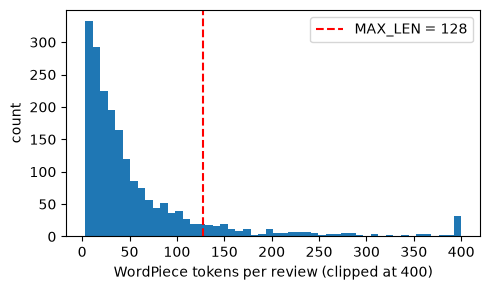

In [17]:
MAX_LEN = 128
n_tokens = np.array([len(ids) for ids in tokenizer(texts_ft)["input_ids"]])
print(f"median length: {np.median(n_tokens):.0f} tokens, "
      f"{(n_tokens <= MAX_LEN).mean():.1%} of reviews have <= {MAX_LEN} tokens")
print("example:", tokenizer.tokenize(texts_ft[0])[:30])

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(np.clip(n_tokens, 0, 400), bins=50)
ax.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
ax.set_xlabel("WordPiece tokens per review (clipped at 400)")
ax.set_ylabel("count")
ax.legend()
plt.tight_layout()
plt.show()

**Data loaders.** We keep the reviews as raw text and tokenise each mini-batch on the fly in the `collate_fn` of
the `DataLoader`. Every batch is padded only up to its own longest review (**dynamic padding**), which is much
cheaper than padding everything to `MAX_LEN`. A batch is a tuple `(input_ids, attention_mask, labels)`.

Dynamic padding only helps if the reviews in a batch have similar lengths. Random batches almost always contain one
long review, so they would still be padded to `MAX_LEN`. The shuffled training loader therefore uses **length
grouping** (like `group_by_length=True` in Hugging Face's `Trainer`): in every epoch the reviews are shuffled,
split into chunks of 50 batches, each chunk is sorted by length and cut into batches, and finally the order of the
batches is shuffled. The batches stay random, but each one needs little padding, so training is about 2-3 times
faster.

In [19]:
def collate(batch: list[tuple[str, int]]) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    batch_texts, batch_labels = zip(*batch)
    enc = tokenizer(list(batch_texts), padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"], torch.tensor(batch_labels, dtype=torch.float32)


class LengthGroupedBatches(torch.utils.data.Sampler):
    """Random batches of indices in which the examples have similar lengths."""

    def __init__(self, lengths: list[int], batch_size: int, seed: int, chunk_batches: int = 50):
        self.lengths = np.asarray(lengths)
        self.batch_size = batch_size
        self.chunk = chunk_batches * batch_size
        self.rng = np.random.default_rng(seed)

    def __len__(self) -> int:
        return -(-len(self.lengths) // self.batch_size)  # ceil division

    def __iter__(self):
        perm = self.rng.permutation(len(self.lengths))
        batches = []
        for s in range(0, len(perm), self.chunk):
            chunk = perm[s : s + self.chunk]
            chunk = chunk[np.argsort(self.lengths[chunk], kind="stable")]
            batches += [chunk[i : i + self.batch_size].tolist() for i in range(0, len(chunk), self.batch_size)]
        for j in self.rng.permutation(len(batches)):
            yield batches[j]


def make_loader(texts_in: list[str], labels_in: np.ndarray, batch_size: int, shuffle: bool) -> DataLoader:
    pairs = list(zip(texts_in, np.asarray(labels_in).tolist()))
    if shuffle:
        sampler = LengthGroupedBatches([len(t) for t in texts_in], batch_size, seed=SEED)
        return DataLoader(pairs, batch_sampler=sampler, collate_fn=collate)
    return DataLoader(pairs, batch_size=batch_size, shuffle=False, collate_fn=collate)


val_loader = make_loader(texts_val, y_val, batch_size=64, shuffle=False)
test_loader = make_loader(texts_test, y_test, batch_size=64, shuffle=False)
_ids, _mask, _y = next(iter(test_loader))
print("first test batch:", tuple(_ids.shape), tuple(_mask.shape), tuple(_y.shape))

first test batch: (64, 8) (64, 8) (64,)


### ✏️ Question 1
Compare WordPiece with the word-level vocabulary of lab NLP-04 (which used `<oov>` for unknown words). How are
the misspelling *"batteryyy"*, the carrier name *"verizon"* and an unseen word such as *"unboxing"* represented
in each case? What does the model gain from subwords, and what is the price?

> ✏️ **Your answer:** *double-click this cell and write your answer here.*

## 4. Feature extraction: a frozen encoder + logistic regression

The simplest way to use a pretrained model is as a fixed **feature extractor**: run every review through the
frozen encoder once, turn the $T$ contextual vectors into a single **sentence vector**, and train a classical
classifier (here logistic regression) on these vectors. Nothing inside the Transformer is changed.

Which sentence vector? In BERT the output at `[CLS]` is only trained for a sentence-level objective *after*
fine-tuning (DistilBERT drops BERT's next-sentence task, so its pretrained `[CLS]` vector was never trained as a
summary at all). For a frozen model, **mean pooling** over the real tokens works better. With the attention mask
$m_t \in \{0, 1\}$:

$$\mathbf{s} = \frac{\sum_{t=1}^{T} m_t\, \mathbf{h}_t}{\sum_{t=1}^{T} m_t}.$$

Padding positions ($m_t = 0$) must be excluded - otherwise the sentence vector would depend on the length of the
longest review in the batch.

### Task 2 - masked mean pooling
`mean_pool(hidden, attention_mask)`: `hidden` has shape `(B, T, d)`, `attention_mask` shape `(B, T)` with
0/1 entries (integer dtype, as returned by the tokenizer). Return the tensor `(B, d)` of averages over the
positions with mask 1. No Python loops.

In [21]:
def mean_pool(hidden: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
    return torch.sum(hidden * attention_mask.unsqueeze(-1), dim=1) / torch.clamp(attention_mask.sum(dim=1, keepdim=True), min=1)

In [22]:
# Tests for Task 2
_h = torch.tensor([[[1.0, 2.0], [3.0, 4.0], [100.0, 100.0]], [[5.0, 6.0], [7.0, 8.0], [9.0, 10.0]]])
_m = torch.tensor([[1, 1, 0], [1, 1, 1]])
_s = mean_pool(_h, _m)
assert _s.shape == (2, 2), f"expected shape (2, 2), got {tuple(_s.shape)}"
assert torch.allclose(_s, torch.tensor([[2.0, 3.0], [7.0, 8.0]])), "padding positions must be ignored"
_h2 = torch.randn(3, 5, 4)
_m2 = torch.tensor([[1, 0, 0, 0, 0], [1, 1, 1, 1, 1], [1, 1, 1, 0, 0]])
_s2 = mean_pool(_h2, _m2)
assert torch.allclose(_s2[0], _h2[0, 0]) and torch.allclose(_s2[2], _h2[2, :3].mean(dim=0))
print("✅ Task 2: all tests passed")

✅ Task 2: all tests passed


Now we embed the fine-tuning and the test reviews with the frozen encoder (`torch.no_grad()`: no gradients
needed) and fit a logistic regression on the 768-dimensional sentence vectors.

In [24]:
@torch.no_grad()
def extract_features(loader: DataLoader) -> tuple[np.ndarray, np.ndarray]:
    """Mean-pooled sentence vectors of the frozen encoder and the labels, in the loader's order."""
    encoder.eval()
    features, ys = [], []
    for ids, mask, y in loader:
        ids, mask = ids.to(device), mask.to(device)
        hidden = encoder(input_ids=ids, attention_mask=mask).last_hidden_state
        features.append(mean_pool(hidden, mask).cpu())
        ys.append(y)
    return torch.cat(features).numpy(), torch.cat(ys).numpy().astype(int)


start = time.time()
_by_len = sorted(range(N_FINETUNE), key=lambda i: len(texts_ft[i]))  # sorted -> less padding, faster
F_ft, yF_ft = extract_features(make_loader([texts_ft[i] for i in _by_len], y_ft[_by_len], 64, shuffle=False))
F_test, yF_test = extract_features(test_loader)
print(f"features: {F_ft.shape} and {F_test.shape} ({time.time() - start:.0f} s)")

frozen_clf = LogisticRegression(max_iter=2000).fit(F_ft, yF_ft)
frozen_proba = frozen_clf.predict_proba(F_test)[:, 1]
frozen_pred = (frozen_proba >= 0.5).astype(int)
assert np.array_equal(yF_test, y_test)  # the test loader keeps the order of y_test
frozen_acc = accuracy(y_test, frozen_pred)
print(f"frozen DistilBERT + logistic regression - test accuracy: {frozen_acc:.3f} "
      f"(majority baseline: {majority_acc:.3f})")

features: (2000, 768) and (2000, 768) (6 s)
frozen DistilBERT + logistic regression - test accuracy: 0.878 (majority baseline: 0.729)


## 5. Theory: fine-tuning

For fine-tuning we add a **classification head** on top of the encoder and train **all** weights - the 66 M of
the encoder and the new head - on our labelled reviews:

```
input_ids, attention_mask ──► DistilBERT encoder ──► h_[CLS] (768) ──► Dropout(0.1) ──► Linear(768 → 1) ──► logit z
```

- We use the output vector at the `[CLS]` position, $\mathbf{h}_1$ = `last_hidden_state[:, 0]`. Through
  self-attention it can look at every token of the review, and fine-tuning teaches the encoder to collect the
  information the head needs there.
- As in lab NLP-04 the head outputs one **logit** $z$ with $P(\text{positive}) = \sigma(z)$, trained with
  `nn.BCEWithLogitsLoss`. (The ready-made `AutoModelForSequenceClassification` does the same with two outputs and
  a softmax.)

Fine-tuning is different from training from scratch - the pretrained weights are already good and we do not want
to destroy them (*catastrophic forgetting*):

- **Small learning rate**: typically $2 \cdot 10^{-5}$ to $5 \cdot 10^{-5}$ with **AdamW** (Adam with decoupled
  weight decay), compared with $10^{-3}$ for a network trained from scratch.
- **Few epochs** (2-4): the model adapts quickly and then starts to overfit the small dataset.
- **Learning-rate warmup**: at the start the head is random, so its gradients flowing into the encoder are large
  and noisy, and Adam's moment estimates are still unreliable. The learning rate therefore grows linearly from 0
  during the first steps (typically 6-10 % of training) and then **decays linearly** to 0:

$$\eta(t) = \eta_{\max} \cdot \begin{cases} t / t_{w} & t < t_w \\ \max\left(0, \dfrac{t_{\text{total}} - t}{t_{\text{total}} - t_w}\right) & t \geq t_w \end{cases}$$

  where $t$ counts optimizer steps (mini-batches), $t_w$ is the number of warmup steps and $t_{\text{total}}$ the
  total number of steps.
- **Gradient clipping**: if the norm of the whole gradient vector exceeds a threshold (1.0), it is rescaled to
  that norm (`nn.utils.clip_grad_norm_`) - this protects the pretrained weights from single bad batches.

### Task 3 - the `SentimentTransformer` model
- `__init__(encoder, dropout=0.1)` stores the given pretrained encoder as `self.encoder` and creates
  `self.dropout` (`nn.Dropout`) and `self.head` (`nn.Linear` from the encoder's hidden size,
  `encoder.config.hidden_size`, to 1).
- `forward(input_ids, attention_mask)` runs the encoder (pass the attention mask!), takes the output vector at
  the first position (`[CLS]`) of `last_hidden_state`, applies dropout and the head, and returns the logits of
  shape `(B,)`.

Taking the encoder as an argument lets the tests use a tiny randomly initialised DistilBERT.

In [26]:
class SentimentTransformer(nn.Module):
    def __init__(self, encoder: nn.Module, dropout: float = 0.1):
        super().__init__()
        self.encoder = encoder
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(encoder.config.hidden_size, 1)

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        hidden = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
        ).last_hidden_state
        cls=hidden[:,0]
        cls=self.dropout(cls)
        logits=self.head(cls).squeeze(-1)
        return logits

In [27]:
# Tests for Task 3
torch.manual_seed(0)
_tiny_config = DistilBertConfig(vocab_size=10, dim=16, hidden_dim=32, n_layers=2, n_heads=2, max_position_embeddings=32)
_tiny = SentimentTransformer(AutoModel.from_config(_tiny_config)).eval()
assert isinstance(_tiny.dropout, nn.Dropout) and _tiny.dropout.p == 0.1
assert isinstance(_tiny.head, nn.Linear) and _tiny.head.in_features == 16 and _tiny.head.out_features == 1
_ids = torch.tensor([[1, 5, 6, 2, 0, 0], [1, 7, 8, 9, 3, 2]])
_mask = (_ids != 0).long()
with torch.no_grad():
    _out = _tiny(_ids, _mask)
    _ref = _tiny.head(_tiny.encoder(input_ids=_ids, attention_mask=_mask).last_hidden_state[:, 0]).squeeze(-1)
    _out_more_pad = _tiny(torch.cat([_ids, torch.zeros(2, 3, dtype=torch.long)], 1), torch.cat([_mask, torch.zeros(2, 3, dtype=torch.long)], 1))
    _out_single = _tiny(_ids[:1, :4], _mask[:1, :4])
assert _out.shape == (2,), f"expected shape (2,), got {tuple(_out.shape)}"
assert torch.allclose(_out, _ref, atol=1e-6), "use the [CLS] vector (position 0) of last_hidden_state"
assert torch.allclose(_out, _out_more_pad, atol=1e-5), "output must not depend on padding - pass the attention mask"
assert torch.allclose(_out[0], _out_single[0], atol=1e-5), "output must not depend on other batch elements"
print("✅ Task 3: all tests passed")

✅ Task 3: all tests passed


### Task 4 - learning-rate schedule with linear warmup and decay
`warmup_linear(step, warmup_steps, total_steps)` returns the **multiplier** of the maximal learning rate from the
formula above: `step / warmup_steps` during warmup, then a linear decay that reaches 0 at `total_steps` and stays
0 afterwards. With `warmup_steps = 0` there is no warmup (the multiplier starts at 1).

PyTorch's `LambdaLR` scheduler multiplies the optimizer's learning rate by this function of the step counter;
`scheduler.step()` is called after every `optimizer.step()`. (`transformers.get_linear_schedule_with_warmup`
implements the same schedule.)

In [56]:
def warmup_linear(step: int, warmup_steps: int, total_steps: int) -> float:
    if warmup_steps==0 and step==0:
        return 1.0
    if step==total_steps:
        return 0.0
    if step<=warmup_steps:
        return step/warmup_steps
    else:
        return  max(0.0,(total_steps-step)/(total_steps-warmup_steps))

In [58]:
# Tests for Task 4
assert warmup_linear(0, 10, 110) == 0.0
assert warmup_linear(5, 10, 110) == 0.5
assert warmup_linear(10, 10, 110) == 1.0
assert warmup_linear(60, 10, 110) == 0.5
assert warmup_linear(110, 10, 110) == 0.0 and warmup_linear(150, 10, 110) == 0.0
assert warmup_linear(0, 0, 100) == 1.0 and warmup_linear(25, 0, 100) == 0.75
_opt = torch.optim.SGD([nn.Parameter(torch.zeros(1))], lr=2.0)
_sched = torch.optim.lr_scheduler.LambdaLR(_opt, lambda s: warmup_linear(s, 4, 20))
_lrs = []
for _ in range(20):
    _lrs.append(_opt.param_groups[0]["lr"])
    _opt.step()
    _sched.step()
assert np.allclose(_lrs[:6], [0.0, 0.5, 1.0, 1.5, 2.0, 1.875])
print("✅ Task 4: all tests passed")

✅ Task 4: all tests passed


### Task 5 - training and prediction
- `train_epoch(model, loader, optimizer, scheduler, loss_fn, max_grad_norm=1.0)` trains for one epoch and returns
  the **mean loss per example**. For every batch `(input_ids, attention_mask, labels)`: move the tensors to
  `device`, zero the gradients, compute the logits and the loss, backpropagate, **clip the gradient norm** of all
  model parameters to `max_grad_norm`, then call `optimizer.step()` and `scheduler.step()`.
- `predict_proba(model, loader)` returns a NumPy array with $P(\text{positive})$ for every example of the loader,
  in the loader's order (evaluation mode, no gradients).

Remember `model.train()` / `model.eval()`: dropout is active only in training mode.

In [60]:
def train_epoch(model, loader, optimizer, scheduler, loss_fn, max_grad_norm=1.0):
    model.train()
    total_loss, n = 0.0, 0
    for input_ids, attention_mask, labels in loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device).float()

        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)
        loss = loss_fn(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item() * labels.size(0)
        n += labels.size(0)
    return total_loss / n


@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    probs = []
    for input_ids, attention_mask, _ in loader:
        logits = model(input_ids.to(device), attention_mask.to(device))
        probs.append(torch.sigmoid(logits).cpu())
    return torch.cat(probs).numpy()

In [61]:
# Tests for Task 5
torch.manual_seed(0)
# toy task on a tiny random DistilBERT: token 3 ("good") -> positive, token 4 ("bad") -> negative
# (1 = [CLS], 2 = [SEP], 0 = [PAD], 5-9 = neutral words)
_toy_ids = torch.tensor([
    [1, 3, 5, 2, 0], [1, 6, 3, 2, 0], [1, 3, 7, 8, 2], [1, 9, 3, 2, 0],
    [1, 4, 5, 2, 0], [1, 6, 4, 2, 0], [1, 4, 7, 8, 2], [1, 9, 4, 2, 0],
])
_toy_y = torch.tensor([1, 1, 1, 1, 0, 0, 0, 0], dtype=torch.float32)
_toy_loader = DataLoader(list(zip(_toy_ids, (_toy_ids != 0).long(), _toy_y)), batch_size=3, shuffle=False)
_toy_model = SentimentTransformer(AutoModel.from_config(_tiny_config)).to(device)
_opt = torch.optim.AdamW(_toy_model.parameters(), lr=3e-3)
_sched = torch.optim.lr_scheduler.LambdaLR(_opt, lambda s: 1.0)
_losses = [train_epoch(_toy_model, _toy_loader, _opt, _sched, nn.BCEWithLogitsLoss()) for _ in range(30)]
assert all(isinstance(loss, float) for loss in _losses)
assert _sched.last_epoch == 30 * len(_toy_loader), "call scheduler.step() once per batch"
assert _losses[-1] < 0.3 * _losses[0], f"loss did not decrease: {_losses[0]:.3f} -> {_losses[-1]:.3f}"
_p = predict_proba(_toy_model, _toy_loader)
assert isinstance(_p, np.ndarray) and _p.shape == (8,)
assert np.all((_p >= 0) & (_p <= 1)), "probabilities must lie in [0, 1]"
assert np.array_equal((_p >= 0.5).astype(int), _toy_y.numpy().astype(int)), "the toy task should be learned perfectly"
assert np.allclose(_p, predict_proba(_toy_model, _toy_loader)), "predictions must be deterministic (eval mode)"
# gradient clipping: with plain SGD (lr = 1) every update is at most max_grad_norm long
_clip_model = SentimentTransformer(AutoModel.from_config(_tiny_config)).to(device)
_before = torch.cat([p.detach().flatten().clone() for p in _clip_model.parameters()])
_sgd = torch.optim.SGD(_clip_model.parameters(), lr=1.0)
train_epoch(_clip_model, _toy_loader, _sgd, torch.optim.lr_scheduler.LambdaLR(_sgd, lambda s: 1.0),
            nn.BCEWithLogitsLoss(), max_grad_norm=1e-3)
_after = torch.cat([p.detach().flatten() for p in _clip_model.parameters()])
assert (_after - _before).norm() <= 3 * 1e-3 + 1e-6, "clip the gradient norm before optimizer.step()"
print(f"toy loss: {_losses[0]:.3f} -> {_losses[-1]:.3f}")
print("✅ Task 5: all tests passed")

toy loss: 0.739 -> 0.013
✅ Task 5: all tests passed


## 6. Fine-tuning DistilBERT
Run the cells below (nothing to implement). We load a **fresh** copy of the pretrained encoder - the frozen one
from section 4 stays untouched - and train for 2 epochs with batch size 16, $\eta_{\max} = 3 \cdot 10^{-5}$ and
10 % warmup. One epoch is 125 optimizer steps; this takes well under a minute on a GPU and about 4 minutes on a
CPU. Note the validation accuracy *before* fine-tuning: the head is still random.

250 steps (25 warmup); validation accuracy before fine-tuning: 0.272
epoch 1: train loss 0.4011, validation accuracy 0.870 (13 s)
epoch 2: train loss 0.1875, validation accuracy 0.878 (12 s)


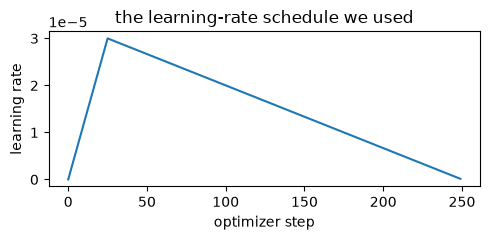

In [62]:
BATCH_SIZE = 16
EPOCHS = 2
LR = 3e-5
WARMUP = 0.1

torch.manual_seed(SEED)
model = SentimentTransformer(AutoModel.from_pretrained(MODEL_NAME)).to(device)
train_loader = make_loader(texts_ft, y_ft, BATCH_SIZE, shuffle=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
warmup_steps = int(WARMUP * total_steps)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: warmup_linear(step, warmup_steps, total_steps))
loss_fn = nn.BCEWithLogitsLoss()

val_acc_before = accuracy(y_val, predict_proba(model, val_loader) >= 0.5)
print(f"{total_steps} steps ({warmup_steps} warmup); validation accuracy before fine-tuning: {val_acc_before:.3f}")

history = {"train_loss": [], "val_acc": []}
for epoch in range(1, EPOCHS + 1):
    start = time.time()
    train_loss = train_epoch(model, train_loader, optimizer, scheduler, loss_fn)
    val_acc = accuracy(y_val, predict_proba(model, val_loader) >= 0.5)
    history["train_loss"].append(train_loss)
    history["val_acc"].append(val_acc)
    print(f"epoch {epoch}: train loss {train_loss:.4f}, validation accuracy {val_acc:.3f} ({time.time() - start:.0f} s)")

_steps = np.arange(total_steps)
fig, ax = plt.subplots(figsize=(5, 2.5))
ax.plot(_steps, [LR * warmup_linear(s, warmup_steps, total_steps) for s in _steps])
ax.set_xlabel("optimizer step")
ax.set_ylabel("learning rate")
ax.set_title("the learning-rate schedule we used")
plt.tight_layout()
plt.show()

## 7. Evaluation on the test set
We compare the fine-tuned model with the frozen feature extractor and the majority baseline on the same 2000 test
reviews. For reference, on the full NLP-04 test set (of which ours is a random subset) the VADER-style lexicon
reached an accuracy of 0.827 (recall of negative reviews 0.555) and the LSTM - trained on 12 600 reviews - 0.863
(recall of negative reviews 0.756).

                         model  accuracy  recall neg  recall pos
             majority baseline     0.729       0.000       1.000
 frozen DistilBERT + log. reg.     0.878       0.751       0.926
         fine-tuned DistilBERT     0.895       0.821       0.922


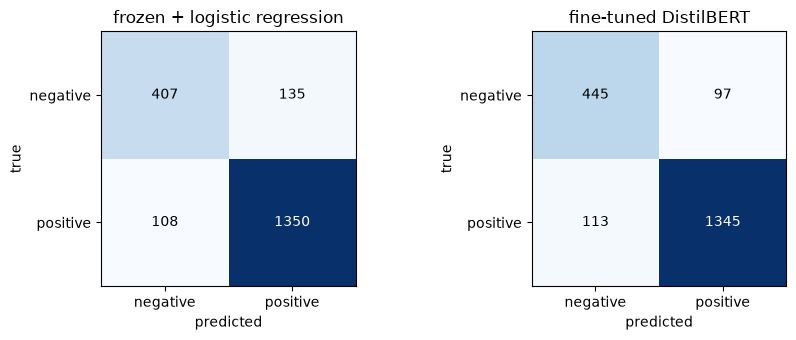

In [63]:
ft_proba = predict_proba(model, test_loader)
ft_pred = (ft_proba >= 0.5).astype(int)
ft_acc = accuracy(y_test, ft_pred)

print(f"{'model':>30}  accuracy  recall neg  recall pos")
print(f"{'majority baseline':>30}  {majority_acc:8.3f}  {0:10.3f}  {1:10.3f}")
for name, pred in (("frozen DistilBERT + log. reg.", frozen_pred), ("fine-tuned DistilBERT", ft_pred)):
    cm = confusion_matrix(y_test, pred)
    print(f"{name:>30}  {accuracy(y_test, pred):8.3f}  {cm[0, 0] / cm[0].sum():10.3f}  {cm[1, 1] / cm[1].sum():10.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, name, pred in zip(axes, ("frozen + logistic regression", "fine-tuned DistilBERT"), (frozen_pred, ft_pred)):
    plot_confusion(ax, confusion_matrix(y_test, pred), name)
plt.tight_layout()
plt.show()

### Error analysis
Test reviews the fine-tuned model gets wrong (with their star rating), and its opinion on the hand-written
reviews from lab NLP-04.

In [64]:
wrong = np.flatnonzero(ft_pred != y_test)
for i in rng.choice(wrong, size=min(8, len(wrong)), replace=False):
    print(f"[{ratings_test[i]}★, P(pos)={ft_proba[i]:.2f}] {texts_test[i][:150]}")


def predict_texts(texts_in: list[str]) -> np.ndarray:
    return predict_proba(model, make_loader(texts_in, np.zeros(len(texts_in)), 64, shuffle=False))


my_reviews = [
    "I love this phone, the battery lasts two days!",
    "Stopped working after a week. Returned it.",
    "Not bad at all for the price.",
    "Not good. The screen is great but the phone keeps restarting.",
    "I expected a lot more from Samsung.",
    "Works fine, but it was clearly used, not new as advertised.",
]
print()
for text, p in zip(my_reviews, predict_texts(my_reviews)):
    print(f"P(positive) = {p:.2f}  {text}")

[5★, P(pos)=0.40] Replaced my l ost phone
[1★, P(pos)=0.54] My daughter needed a new phone and wanted the same device that she had before. However, after purchasing this phone i uncovered that it would not work
[1★, P(pos)=0.90] Paid for a stainless steel, sapphire crystal Apple Watch. Received a black sport Apple Watch. Just buy a new one, this isn't worth the hassle.
[5★, P(pos)=0.07] What's not to like I can drop in a puddle and still make phone calls.
[4★, P(pos)=0.04] Will not allow me to send picture messages to anybody but like the phone.
[3★, P(pos)=0.02] I've had this type of phone before and I like it. This one however has given me a couple of problems. I can't charge it in my car and text at the same
[2★, P(pos)=0.99] Loved the idea of the phone, was very upset when the phone was picky about the charger I used and would not charge on any of my two car chargers. Also
[1★, P(pos)=0.65] Is a good smartphone, is very fast, friendly but at least mine cell phone have a big problem

`### ✏️ Question 2
Compare the frozen feature extractor with the fine-tuned model (accuracy, recall of the negative class,
confusion matrices). Why is fine-tuning better here, although both start from the same pretrained weights and
see the same 2000 labelled reviews? In which situations would you still choose feature extraction?

> ✏️ **Your answer:** *double-click this cell and write your answer here.*

### ✏️ Question 3
The LSTM of lab NLP-04 was trained on 12 600 reviews; DistilBERT was fine-tuned on only 2000 for 2 epochs. Compare
their test accuracies and their behaviour on the hand-written reviews (especially negation and contrast). Where
does the knowledge that lets the Transformer win with six times less labelled data come from? What do we pay for
it?

> ✏️ **Your answer:** *double-click this cell and write your answer here.*

### ✏️ Question 4
Why are fine-tuning learning rates so small ($2 \cdot 10^{-5}$-$5 \cdot 10^{-5}$) compared with training from
scratch ($10^{-3}$)? What would you expect if we fine-tuned with `LR = 1e-3`, and what is the warmup good for?

> ✏️ **Your answer:** *double-click this cell and write your answer here.*

## Summary
- **Transfer learning**: a Transformer encoder pretrained on raw text with masked language modelling already
  "knows" a lot of English; fine-tuning adapts it to a task with little labelled data.
- The Hugging Face `transformers` library loads matching tokenizers and models from the Hub by name
  (`AutoTokenizer`, `AutoModel`).
- **WordPiece** splits rare words into known subword pieces (`##` marks a continuation), so there is practically
  no out-of-vocabulary problem. Inputs get `[CLS]`/`[SEP]`, are padded per batch and come with an **attention
  mask** that hides the padding.
- **Feature extraction**: frozen encoder → masked mean pooling → simple classifier. Cheap and simple, but the
  features are not adapted to the task.
- **Fine-tuning**: classification head on the `[CLS]` vector, all weights trained with AdamW, a small learning
  rate with warmup and linear decay, gradient clipping and only a few epochs.

**Going further**
- On a GPU, fine-tune on all 12 600 training reviews (`N_FINETUNE = len(train_idx)`) and on the full test set -
  how much does more labelled data still help?
- Replace our model and loop by the library's own tools: `AutoModelForSequenceClassification.from_pretrained(
  MODEL_NAME, num_labels=2)` and the `Trainer` API.
- Try a model that is already fine-tuned for sentiment on movie reviews (SST-2) without any training:
  `transformers.pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")`. How
  well does it transfer to phone reviews?
- Freeze the encoder's embeddings and lower layers (`requires_grad_(False)`) and fine-tune only the top layers -
  compare accuracy and speed.
- Try other pretrained models from the Hub (e.g. `bert-base-uncased`, `roberta-base`) or parameter-efficient
  fine-tuning with LoRA (`peft` library).